# Instituto Federal do Espírito Santo (IFES) – Campus Serra
### Programa de Pós-Graduação em Computação Aplicada (PPComp) – Mestrado

**Disciplina:** Redes Neurais Artificiais (2026/2)
**Professor:** Francisco de Assis Boldt
**Aluno:** Leonardo Cruz de Andrade
**Data de entrega:** 18 de novembro de 2026

## Atividade 01 – MLP com backpropagation e comparação com o Scikit-Learn

Neste notebook eu implemento um Multi-Layer Perceptron em NumPy, partindo do código desenvolvido nos dois vídeos da Aula 05, e comparo o resultado com o `MLPClassifier` do Scikit-Learn. A rede aceita como parâmetros o número de camadas ocultas, o número de neurônios em cada uma e a função de ativação de cada camada.

**Organização do notebook**
1. Resumo dos vídeos da Aula 05
2. Equações do forward e do backward
3. Implementação e verificação do gradiente
4. XOR com dois neurônios ocultos
5. Base sintética com 10 centros
6. Base Iris e comparação com o Scikit-Learn
7. Conclusões

Código de referência da disciplina: [fboldt/aulasann](https://github.com/fboldt/aulasann).

## 1. Resumo dos vídeos da Aula 05

**Vídeo 1 – implementação simplificada (uma camada oculta).** O ponto de partida é o problema do XOR, que um perceptron simples não resolve porque as classes não são linearmente separáveis. Também não adianta empilhar camadas lineares, já que $W_2 (W_1 X + b_1) + b_2$ continua sendo uma transformação afim. O que resolve é colocar uma ativação não linear na camada oculta; no vídeo foi usada a $\tanh$, numa rede 2-2-1. O professor deduz o gradiente dessa rede e mostra que o erro chega à camada oculta pelos pesos transpostos da camada seguinte, sem a linha do bias, multiplicado pela derivada da ativação:

$$\delta^{(1)} = \left( \delta^{(2)} \, (W^{(2)}_{[1:]})^T \right) \odot f'_1(Z^{(1)})$$

**Vídeo 2 – várias camadas.** Os pesos passam a ficar numa lista (`self.Ws`). No forward são guardadas as entradas de cada camada já com o bias (`self.A`) e as pré-ativações (`self.Z`), e o backward percorre essa lista de trás para frente acumulando $\nabla_{W^{(l)}} = (A^{(l-1)})^T \delta^{(l)}$. No final do vídeo a rede é testada numa base mais difícil, com 10 centros e rótulo dado por `y % 2`: com 2 neurônios ocultos o ajuste fica ruim e melhora quando se aumenta o número de neurônios ou de camadas. O professor comenta ainda que a rede só usava a $\tanh$ e só tratava problemas binários.

Na versão deste notebook, cada camada pode ter a sua ativação e a rede trata problemas com mais de duas classes usando codificação one-hot, como em `aula05d - Multi Classe`.

## 2. Equações

Considere a entrada $X \in \mathbb{R}^{N \times d}$, com $N$ amostras e $d$ atributos, e uma rede com camadas de tamanhos $[n_0, n_1, \dots, n_L]$, onde $n_0 = d$ e $n_L$ é o número de saídas.

Assim como no código da aula, o bias é tratado acrescentando uma coluna de uns à entrada de cada camada:
$$\tilde{A}^{(l-1)} = [\mathbf{1}_{N \times 1} \mid A^{(l-1)}] \in \mathbb{R}^{N \times (n_{l-1} + 1)}$$
Com isso, a matriz de pesos da camada $l$ fica $W^{(l)} \in \mathbb{R}^{(n_{l-1} + 1) \times n_l}$, e a linha 0 guarda os pesos do bias.

**Forward.** Partindo de $A^{(0)} = X$, para $l = 1, \dots, L$:
$$Z^{(l)} = \tilde{A}^{(l-1)} W^{(l)}, \qquad A^{(l)} = f_l(Z^{(l)})$$
sendo $f_l$ a ativação escolhida para a camada $l$ (a de saída inclusive).

**Custo.** Uso o erro quadrático médio:
$$J(W) = \frac{1}{2N} \sum_{k=1}^N \lVert \hat{y}^{(k)} - y^{(k)} \rVert^2$$

**Backward.** Na camada de saída, $\delta^{(L)} = (A^{(L)} - Y) \odot f'_L(Z^{(L)})$. Nas camadas ocultas, de $l = L-1$ até $1$:
$$\delta^{(l)} = \left( \delta^{(l+1)} \, (W^{(l+1)}_{[1:, :]})^T \right) \odot f'_l(Z^{(l)})$$
A linha 0 de $W^{(l+1)}$ fica de fora porque liga o bias, que é constante e não tem nada antes dele para receber erro. O gradiente e a atualização (gradiente descendente com todas as amostras a cada época) são:
$$\nabla_{W^{(l)}} J = \frac{1}{N} (\tilde{A}^{(l-1)})^T \delta^{(l)}, \qquad W^{(l)} \leftarrow W^{(l)} - \eta \, \nabla_{W^{(l)}} J$$

**Alvos.** Em problemas binários a rede tem uma saída; com mais classes, uma saída por classe, e a predição é o $\arg\max$. Os valores dos alvos dependem da ativação de saída: $\{-1, +1\}$ para `linear` e `tanh`, e $\{0, 1\}$ para `sigmoid`.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_blobs, load_iris
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 105

In [2]:
# Funções de ativação e derivadas
def _sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -30.0, 30.0)))  # o clip evita overflow no exp

def _sigmoid_deriv(z):
    s = _sigmoid(z)
    return s * (1.0 - s)

def _tanh(z):
    return np.tanh(z)

def _tanh_deriv(z):
    return 1.0 - np.tanh(z) ** 2

def _relu(z):
    return np.maximum(0.0, z)

def _relu_deriv(z):
    return (z > 0.0).astype(float)

def _linear(z):
    return z

def _linear_deriv(z):
    return np.ones_like(z, dtype=float)

ACTIVATIONS = {
    'tanh': (_tanh, _tanh_deriv),
    'sigmoid': (_sigmoid, _sigmoid_deriv),
    'relu': (_relu, _relu_deriv),
    'linear': (_linear, _linear_deriv),
}

# Na saída só uso ativações cuja faixa de valores contém os alvos
OUTPUT_ACTIVATIONS = ('linear', 'tanh', 'sigmoid')


def include_bias(X):
    return np.c_[np.ones((X.shape[0], 1)), X]

def one_hot_encode(y, labels, low=-1.0, high=1.0):
    y_hot = np.full((y.shape[0], len(labels)), low, dtype=float)
    for idx, label in enumerate(labels):
        y_hot[y == label, idx] = high
    return y_hot

In [3]:
class CustomMLPClassifier(BaseEstimator, ClassifierMixin):
    '''
    MLP treinado por backpropagation com gradiente descendente (todas as amostras por época)
    e custo quadrático.

    n_hidden          : neurônios de cada camada oculta, ex.: [16, 8] -> duas camadas ocultas
    activations       : ativação de cada camada oculta (lista) ou uma única string para todas;
                        'tanh', 'sigmoid', 'relu' ou 'linear'
    output_activation : ativação da camada de saída: 'linear', 'tanh' ou 'sigmoid'
    max_iter          : número de épocas
    learning_rate     : taxa de aprendizado
    tol               : para o treino se a variação do custo ficar abaixo de tol (0 desliga)
    random_state      : semente usada na inicialização dos pesos
    '''
    def __init__(self, n_hidden=(4, 2), activations=('relu', 'tanh'), output_activation='linear',
                 max_iter=5000, learning_rate=0.01, tol=0.0, random_state=42):
        self.n_hidden = n_hidden
        self.activations = activations
        self.output_activation = output_activation
        self.max_iter = max_iter
        self.learning_rate = learning_rate
        self.tol = tol
        self.random_state = random_state

    def _setup_activations(self):
        n_layers = len(self.n_hidden)
        if isinstance(self.activations, str):
            names = [self.activations] * n_layers
        else:
            names = list(self.activations)
            if len(names) != n_layers:
                raise ValueError(f"Foram informadas {len(names)} ativações para {n_layers} camadas ocultas.")
        out_name = self.output_activation.lower()
        if out_name not in OUTPUT_ACTIVATIONS:
            raise ValueError(f"Ativação de saída '{self.output_activation}' inválida. Opções: {OUTPUT_ACTIVATIONS}")
        names = [n.lower() for n in names] + [out_name]
        for n in names:
            if n not in ACTIVATIONS:
                raise ValueError(f"Ativação '{n}' não reconhecida. Opções: {list(ACTIVATIONS)}")
        self.layer_activations_ = names
        self.funcs_ = [ACTIVATIONS[n][0] for n in names]
        self.derivs_ = [ACTIVATIONS[n][1] for n in names]
        # sigmoid na saída -> alvos {0, 1}; linear ou tanh -> alvos {-1, 1}
        self.target_low_ = 0.0 if out_name == 'sigmoid' else -1.0
        self.target_high_ = 1.0

    def forward(self, X):
        self.A = []
        self.Z = []
        AUX = X.copy()
        for W, f in zip(self.Ws, self.funcs_):
            self.A.append(include_bias(AUX))
            self.Z.append(self.A[-1] @ W)
            AUX = f(self.Z[-1])
        return AUX

    def _gradients(self, y, y_pred):
        # usa os A e Z guardados no último forward
        grads = []
        output_delta = (y_pred - y) * self.derivs_[-1](self.Z[-1])
        grads.append(self.A[-1].T @ output_delta)
        for i in range(len(self.Ws) - 1, 0, -1):
            # a linha 0 de W é o bias e não leva erro para a camada anterior
            input_delta = (output_delta @ self.Ws[i][1:].T) * self.derivs_[i - 1](self.Z[i - 1])
            grads.insert(0, self.A[i - 1].T @ input_delta)
            output_delta = input_delta.copy()
        n = y.shape[0]
        return [g / n for g in grads]

    def backward(self, y, y_pred):
        for W, g in zip(self.Ws, self._gradients(y, y_pred)):
            W -= self.learning_rate * g
        return self

    def _encode_targets(self, y):
        if len(self.labels) == 2:
            return np.where(y == self.labels[1], self.target_high_, self.target_low_).reshape(-1, 1)
        return one_hot_encode(y, self.labels, self.target_low_, self.target_high_)

    def fit(self, X, y):
        rng = np.random.RandomState(self.random_state)
        self._setup_activations()
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        self.labels = np.unique(y)
        self.classes_ = self.labels
        Y = self._encode_targets(y)

        # pesos iniciais com variância proporcional a 2 / (entradas + 1), em vez de N(0, 1),
        # para não saturar tanh e sigmoid logo no início
        sizes = [X.shape[1]] + list(self.n_hidden) + [Y.shape[1]]
        self.Ws = [rng.randn(sizes[i] + 1, sizes[i + 1]) * np.sqrt(2.0 / (sizes[i] + 1))
                   for i in range(len(sizes) - 1)]

        self.loss_history_ = []
        for epoch in range(self.max_iter):
            y_pred = self.forward(X)
            loss = np.sum((y_pred - Y) ** 2) / (2 * X.shape[0])
            self.loss_history_.append(loss)
            if self.tol > 0 and epoch > 20 and abs(self.loss_history_[-2] - loss) < self.tol:
                break
            self.backward(Y, y_pred)
        self.n_iter_ = len(self.loss_history_)
        return self

    def predict(self, X):
        out = self.forward(np.asarray(X, dtype=float))
        if len(self.labels) == 2:
            threshold = (self.target_low_ + self.target_high_) / 2.0
            return np.where(out.ravel() >= threshold, self.labels[1], self.labels[0])
        return self.labels[np.argmax(out, axis=1)]

    def score(self, X, y):
        return accuracy_score(y, self.predict(X))

## 3. Conferindo a implementação

Antes dos experimentos, dois testes rápidos. No primeiro, monto uma rede com três camadas ocultas de tamanhos diferentes e uma ativação diferente em cada uma, para ver como ficam as matrizes de pesos, e testo algumas configurações erradas para conferir se a classe reclama.

No segundo, comparo o gradiente calculado pelo backward com uma aproximação por diferenças finitas:
$$\frac{\partial J}{\partial w} \approx \frac{J(w + \varepsilon) - J(w - \varepsilon)}{2\varepsilon}, \qquad \varepsilon = 10^{-5}$$
Se o backward estiver certo, o erro relativo entre os dois tem de ficar muito pequeno (algo abaixo de $10^{-7}$). Deixei a ReLU fora desse teste porque ela não tem derivada em zero.

In [4]:
X_demo, y_demo = make_blobs(n_samples=60, centers=3, n_features=4, random_state=0)

demo = CustomMLPClassifier(n_hidden=[8, 5, 3], activations=['relu', 'sigmoid', 'tanh'],
                           output_activation='tanh', max_iter=0).fit(X_demo, y_demo)
print("Ativações por camada:", demo.layer_activations_)
for i, W in enumerate(demo.Ws, start=1):
    print(f"  W{i}: {W.shape}")

for kwargs in [dict(n_hidden=[4, 2], activations=['tanh']),
               dict(n_hidden=[4], activations=['softplus']),
               dict(n_hidden=[4], activations=['tanh'], output_activation='relu')]:
    try:
        CustomMLPClassifier(max_iter=1, **kwargs).fit(X_demo, y_demo)
    except ValueError as e:
        print(f"  {kwargs} -> ValueError: {e}")

Ativações por camada: ['relu', 'sigmoid', 'tanh', 'tanh']
  W1: (5, 8)
  W2: (9, 5)
  W3: (6, 3)
  W4: (4, 3)
  {'n_hidden': [4, 2], 'activations': ['tanh']} -> ValueError: Foram informadas 1 ativações para 2 camadas ocultas.
  {'n_hidden': [4], 'activations': ['softplus']} -> ValueError: Ativação 'softplus' não reconhecida. Opções: ['tanh', 'sigmoid', 'relu', 'linear']
  {'n_hidden': [4], 'activations': ['tanh'], 'output_activation': 'relu'} -> ValueError: Ativação de saída 'relu' inválida. Opções: ('linear', 'tanh', 'sigmoid')


In [5]:
def gradient_check(model, X, y, eps=1e-5):
    model.set_params(max_iter=0).fit(X, y)   # só inicializa os pesos
    Y = model._encode_targets(y)
    J = lambda: np.sum((model.forward(X) - Y) ** 2) / (2 * X.shape[0])
    analytic = model._gradients(Y, model.forward(X))
    errors = []
    for W, G in zip(model.Ws, analytic):
        numeric = np.zeros_like(W)
        for idx in np.ndindex(W.shape):
            original = W[idx]
            W[idx] = original + eps; j_plus = J()
            W[idx] = original - eps; j_minus = J()
            W[idx] = original
            numeric[idx] = (j_plus - j_minus) / (2 * eps)
        errors.append(np.linalg.norm(G - numeric) / (np.linalg.norm(G) + np.linalg.norm(numeric)))
    return errors

X_gc, y_gc = make_blobs(n_samples=30, centers=3, n_features=4, random_state=1)
X_gc = StandardScaler().fit_transform(X_gc)
configs_gc = [
    dict(n_hidden=[5],       activations=['tanh'],                      output_activation='linear'),
    dict(n_hidden=[6, 4],    activations=['sigmoid', 'tanh'],           output_activation='sigmoid'),
    dict(n_hidden=[6, 5, 4], activations=['tanh', 'sigmoid', 'linear'], output_activation='tanh'),
]
for cfg in configs_gc:
    errs = gradient_check(CustomMLPClassifier(random_state=7, **cfg), X_gc, y_gc)
    print(f"{str(cfg['n_hidden']):10s} {str(cfg['activations'] + [cfg['output_activation']]):42s} "
          f"erro relativo por camada: {['%.1e' % e for e in errs]}")

[5]        ['tanh', 'linear']                         erro relativo por camada: ['3.7e-11', '2.5e-11']
[6, 4]     ['sigmoid', 'tanh', 'sigmoid']             erro relativo por camada: ['1.0e-10', '5.9e-11', '3.4e-11']
[6, 5, 4]  ['tanh', 'sigmoid', 'linear', 'tanh']      erro relativo por camada: ['2.6e-10', '2.5e-10', '5.3e-11', '4.3e-11']


## 4. XOR com dois neurônios ocultos

Aqui repito o exemplo do Vídeo 1: quatro grupos de pontos nos cantos do quadrado unitário, rotulados pelo XOR, e uma rede 2-2-1 com saída linear. Testei três ativações na camada oculta. A taxa de aprendizado foi diferente para cada uma: 0,5 para `tanh`, 1,0 para `sigmoid` (a derivada da sigmoide não passa de 0,25, então o passo precisa ser maior) e 0,1 para `relu`, que divergia com valores mais altos.

Nos primeiros testes percebi que, com só dois neurônios, o resultado muda bastante conforme a inicialização dos pesos. Por isso, além das fronteiras de decisão para uma semente fixa (`random_state=3`), a segunda célula treina a rede com 20 sementes e conta quantas vezes ela acerta todos os pontos, com 2 e com 4 neurônios ocultos.

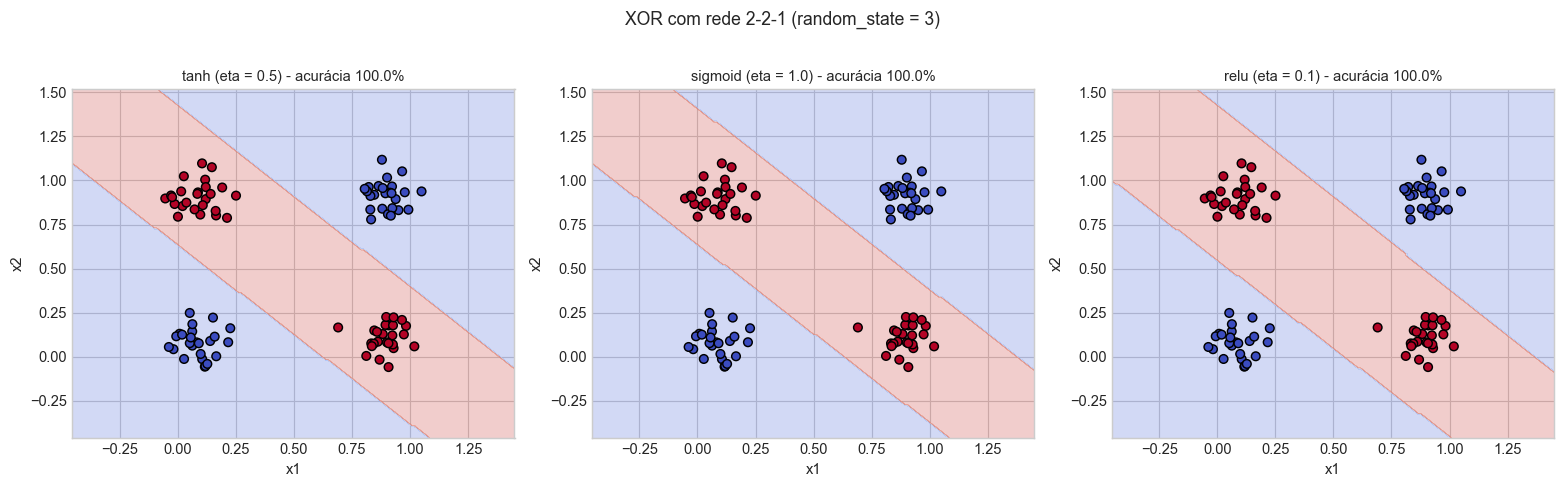

In [6]:
def createLogicalDataset(n=80, func=lambda a, b: bool(a) != bool(b), random_state=42):
    X, _ = make_blobs(n_samples=n, centers=[[0.1, 0.1], [0.9, 0.1], [0.1, 0.9], [0.9, 0.9]],
                      n_features=2, cluster_std=0.08, random_state=random_state)
    y = np.array([func(a > 0.5, b > 0.5) for a, b in X], dtype=int) * 2 - 1
    return X, y

def plot_decision_boundary(model, X, y, title, ax, margin=0.4, steps=200):
    x_min, x_max = X[:, 0].min() - margin, X[:, 0].max() + margin
    y_min, y_max = X[:, 1].min() - margin, X[:, 1].max() + margin
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, steps), np.linspace(y_min, y_max, steps))
    preds = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, preds, alpha=0.25, cmap=plt.cm.coolwarm)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='k', s=35)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")

X_xor, y_xor = createLogicalDataset(n=100, random_state=42)

XOR_LR = {'tanh': 0.5, 'sigmoid': 1.0, 'relu': 0.1}
XOR_ITER = 5000
SEED_PLOT = 3

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (act, lr) in zip(axes, XOR_LR.items()):
    mlp_xor = CustomMLPClassifier(n_hidden=[2], activations=[act], learning_rate=lr,
                                  max_iter=XOR_ITER, random_state=SEED_PLOT).fit(X_xor, y_xor)
    acc = mlp_xor.score(X_xor, y_xor)
    plot_decision_boundary(mlp_xor, X_xor, y_xor, f"{act} (eta = {lr}) - acurácia {acc * 100:.1f}%", ax)
plt.suptitle(f"XOR com rede 2-2-1 (random_state = {SEED_PLOT})", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

In [7]:
N_SEEDS = 20
rows = []
for n_neurons in [2, 4]:
    for act, lr in XOR_LR.items():
        accs = np.array([CustomMLPClassifier(n_hidden=[n_neurons], activations=[act], learning_rate=lr,
                                             max_iter=XOR_ITER, random_state=s).fit(X_xor, y_xor).score(X_xor, y_xor)
                         for s in range(N_SEEDS)])
        rows.append({'neurônios ocultos': n_neurons, 'ativação': act, 'eta': lr,
                     'acertou tudo': f"{int((accs == 1).sum())}/{N_SEEDS}",
                     'acurácia média (%)': round(accs.mean() * 100, 1),
                     'pior acurácia (%)': round(accs.min() * 100, 1)})
xor_table = pd.DataFrame(rows)
xor_table

,neurônios ocultos,ativação,eta,acertou tudo,acurácia média (%),pior acurácia (%)
0,2,tanh,0.5,17/20,95.6,67.0
1,2,sigmoid,1.0,16/20,90.9,50.0
2,2,relu,0.1,5/20,73.8,50.0
3,4,tanh,0.5,20/20,100.0,100.0
4,4,sigmoid,1.0,20/20,100.0,100.0
5,4,relu,0.1,14/20,88.8,50.0


## 5. Base com 10 centros

Este é o teste do final do Vídeo 2: `make_blobs` com 10 centros e a classe definida pela paridade do centro (`y % 2`). Experimentei algumas sementes e em boa parte delas as duas classes acabam quase separáveis por uma linha, o que tira a graça do teste. Fiquei com `random_state=4`, em que isso não acontece. Os atributos foram padronizados.

Comparei três redes, todas com $\eta = 0{,}1$, 6000 épocas e `random_state=0`:
- rasa: `n_hidden=[2]` com `tanh`;
- larga: `n_hidden=[16]` com `relu`;
- profunda: `n_hidden=[16, 8]` com `relu` na primeira camada e `tanh` na segunda.

Como no vídeo, a acurácia é medida nos próprios dados de treino, porque a ideia aqui é ver quanto cada rede consegue se ajustar. A generalização fica para a seção seguinte.

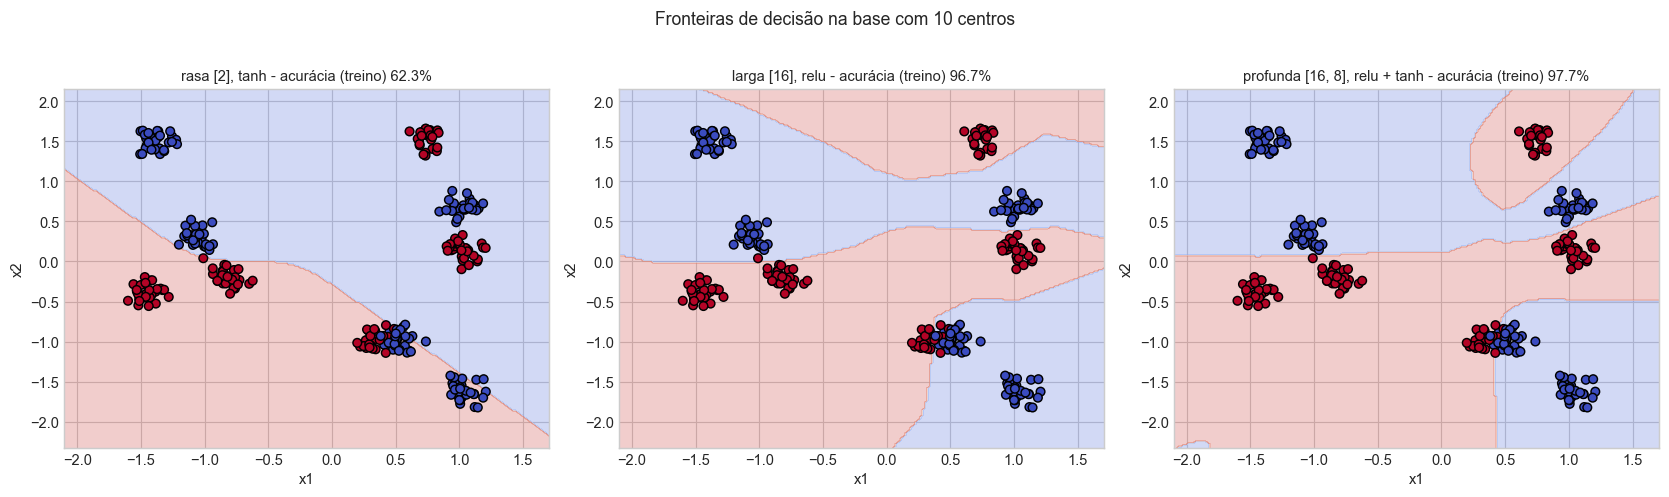

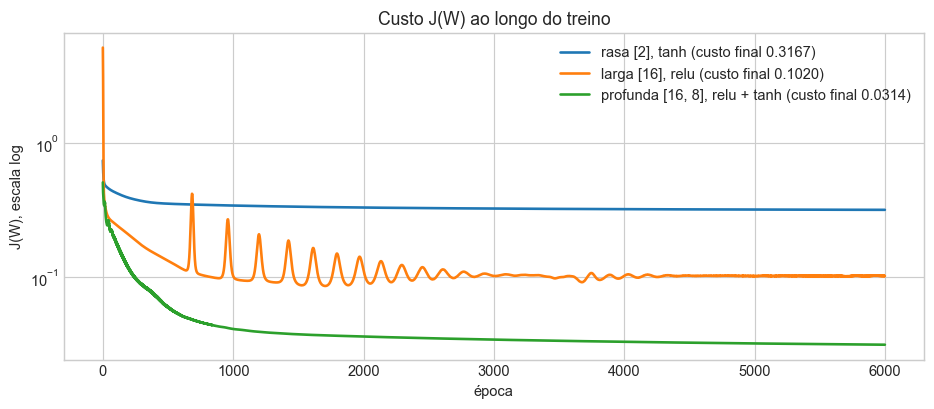

In [8]:
X_raw, y_raw = make_blobs(n_samples=300, centers=10, n_features=2, cluster_std=0.6, random_state=4)
X_comp = StandardScaler().fit_transform(X_raw)
y_comp = np.where(y_raw % 2 == 0, 1, -1)

configs = [
    {"name": "rasa [2], tanh",               "hidden": [2],     "acts": ['tanh']},
    {"name": "larga [16], relu",             "hidden": [16],    "acts": ['relu']},
    {"name": "profunda [16, 8], relu + tanh", "hidden": [16, 8], "acts": ['relu', 'tanh']},
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
trained_models = []
for ax, cfg in zip(axes, configs):
    model = CustomMLPClassifier(n_hidden=cfg["hidden"], activations=cfg["acts"],
                                learning_rate=0.1, max_iter=6000, random_state=0).fit(X_comp, y_comp)
    acc = model.score(X_comp, y_comp)
    trained_models.append((cfg["name"], model, acc))
    plot_decision_boundary(model, X_comp, y_comp, f"{cfg['name']} - acurácia (treino) {acc * 100:.1f}%", ax, margin=0.5)
plt.suptitle("Fronteiras de decisão na base com 10 centros", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
for name, model, acc in trained_models:
    plt.plot(model.loss_history_, label=f"{name} (custo final {model.loss_history_[-1]:.4f})", linewidth=1.8)
plt.title("Custo J(W) ao longo do treino")
plt.xlabel("época")
plt.ylabel("J(W), escala log")
plt.yscale('log')
plt.legend()
plt.tight_layout()
plt.show()

## 6. Base Iris e comparação com o Scikit-Learn

Para a comparação usei a Iris (150 amostras, 4 atributos, 3 classes), a mesma base do notebook `aula05e - MLP Iris`. Avaliei de duas formas: separando 30% dos dados para teste (estratificado, `random_state=42`) e com validação cruzada estratificada de 5 folds. A padronização fica dentro de um `Pipeline`, assim a média e o desvio de cada partição são calculados só com os dados de treino dela.

Para a comparação ser justa, configurei o `MLPClassifier` o mais próximo possível da minha rede: mesma arquitetura `(12, 6)`, ativação `tanh`, `solver='sgd'` com taxa fixa de 0,05, sem momento, com todas as amostras de treino em cada passo (`batch_size` igual ao tamanho do treino), sem regularização (`alpha=0`) e 3000 épocas. A diferença que sobra é que o Scikit-Learn usa softmax com entropia cruzada na saída e outra inicialização de pesos.

Incluí ainda dois modelos como referência: minha rede com `relu` na primeira camada oculta e `tanh` na segunda (o `MLPClassifier` usa a mesma ativação em todas as camadas ocultas, então não dá para reproduzir isso nele) e o `MLPClassifier` com a configuração padrão (ReLU, Adam e `alpha=1e-4`).

In [9]:
X_iris, y_iris = load_iris(return_X_y=True)
class_names = load_iris().target_names

X_train, X_test, y_train, y_test = train_test_split(X_iris, y_iris, test_size=0.30,
                                                    random_state=42, stratify=y_iris)
print(f"treino: {X_train.shape}, teste: {X_test.shape}")

LR_IRIS, ITER_IRIS = 0.05, 3000
models = {
    "minha rede (tanh, tanh)": CustomMLPClassifier(
        n_hidden=(12, 6), activations='tanh', learning_rate=LR_IRIS, max_iter=ITER_IRIS, random_state=42),
    "sklearn equivalente": MLPClassifier(
        hidden_layer_sizes=(12, 6), activation='tanh', solver='sgd', learning_rate='constant',
        learning_rate_init=LR_IRIS, momentum=0.0, nesterovs_momentum=False, batch_size=len(X_train),
        alpha=0.0, max_iter=ITER_IRIS, n_iter_no_change=ITER_IRIS, random_state=42),
    "minha rede (relu, tanh)": CustomMLPClassifier(
        n_hidden=(12, 6), activations=('relu', 'tanh'), learning_rate=LR_IRIS, max_iter=ITER_IRIS, random_state=42),
    "sklearn padrão": MLPClassifier(hidden_layer_sizes=(12, 6), max_iter=2000, random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results, holdout_preds, cv_scores = [], {}, {}
for name, est in models.items():
    t0 = time.time()
    pipe = make_pipeline(StandardScaler(), est).fit(X_train, y_train)
    fit_time = time.time() - t0
    holdout_preds[name] = pipe.predict(X_test)
    scores = cross_validate(make_pipeline(StandardScaler(), est), X_iris, y_iris, cv=cv, scoring='accuracy')['test_score']
    cv_scores[name] = scores
    results.append({"modelo": name,
                    "teste (%)": round(accuracy_score(y_test, holdout_preds[name]) * 100, 2),
                    "CV média (%)": round(scores.mean() * 100, 2),
                    "CV desvio (%)": round(scores.std() * 100, 2),
                    "CV por fold (%)": np.round(scores * 100, 1).tolist(),
                    "tempo de treino (s)": round(fit_time, 2)})

results_df = pd.DataFrame(results)
results_df

treino: (105, 4), teste: (45, 4)


,modelo,teste (%),CV média (%),CV desvio (%),CV por fold (%),tempo de treino (s)
0,"minha rede (tanh, tanh)",91.11,95.33,3.40,"[100.0, 96.7, 93.3, 96.7, 90.0]",0.58
1,sklearn equivalente,88.89,94.67,5.42,"[100.0, 96.7, 90.0, 100.0, 86.7]",1.09
2,"minha rede (relu, tanh)",93.33,95.33,4.52,"[100.0, 100.0, 90.0, 96.7, 90.0]",0.45
3,sklearn padrão,91.11,95.33,4.52,"[100.0, 96.7, 90.0, 100.0, 90.0]",0.33


In [10]:
for name in ["minha rede (tanh, tanh)", "sklearn equivalente"]:
    print(f"{name} - conjunto de teste")
    print(classification_report(y_test, holdout_preds[name], target_names=class_names, digits=3))

diff = (cv_scores["minha rede (tanh, tanh)"] - cv_scores["sklearn equivalente"]) * 100
print("Diferença por fold (minha rede - sklearn), em pontos percentuais:", np.round(diff, 1))
print(f"Cada fold tem 30 amostras, então uma amostra vale {100 / 30:.1f} p.p.")

minha rede (tanh, tanh) - conjunto de teste
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      0.824     0.933     0.875        15
   virginica      0.923     0.800     0.857        15

    accuracy                          0.911        45
   macro avg      0.916     0.911     0.911        45
weighted avg      0.916     0.911     0.911        45

sklearn equivalente - conjunto de teste
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      0.778     0.933     0.848        15
   virginica      0.917     0.733     0.815        15

    accuracy                          0.889        45
   macro avg      0.898     0.889     0.888        45
weighted avg      0.898     0.889     0.888        45

Diferença por fold (minha rede - sklearn), em pontos percentuais: [ 0.   0.   3.3 -3.3  3.3]
Cada fold tem 30 amostras, então uma amostra vale 3.3 p.p.


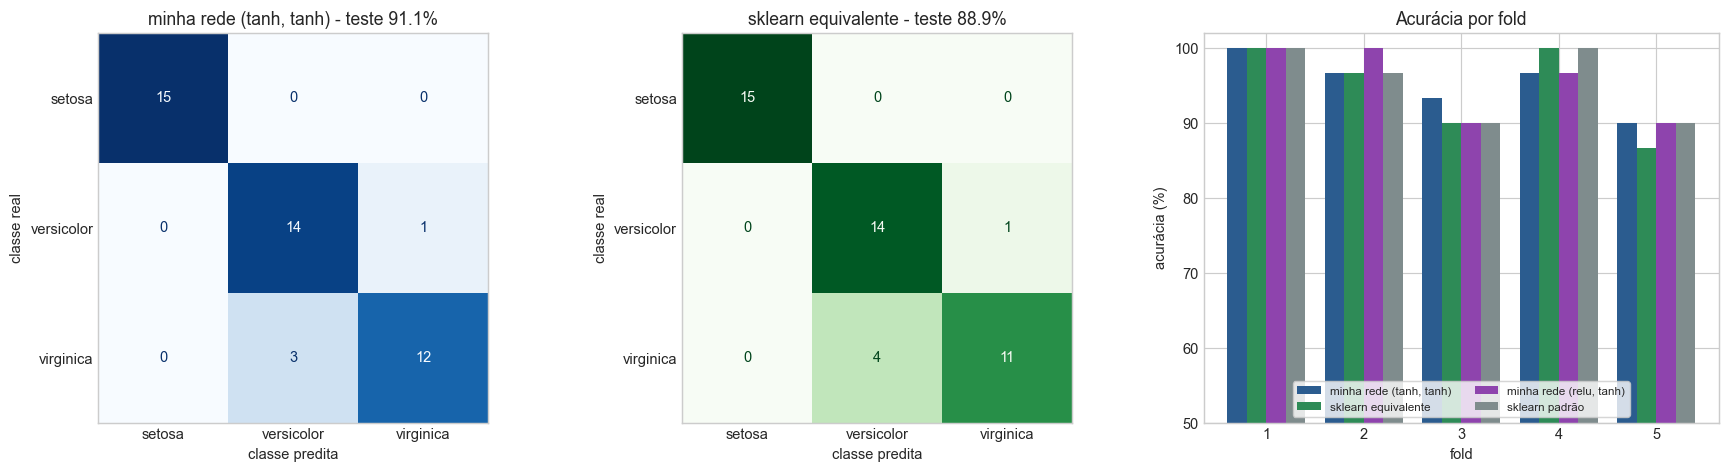

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, name, cmap in [(axes[0], "minha rede (tanh, tanh)", 'Blues'), (axes[1], "sklearn equivalente", 'Greens')]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, holdout_preds[name]), display_labels=class_names).plot(
        ax=ax, cmap=cmap, colorbar=False)
    ax.set_title(f"{name} - teste {accuracy_score(y_test, holdout_preds[name]) * 100:.1f}%")
    ax.set_xlabel("classe predita")
    ax.set_ylabel("classe real")
    ax.grid(False)

folds = np.arange(1, 6)
width = 0.2
for k, (name, color) in enumerate(zip(models, ['#2b5c8f', '#2e8b57', '#8e44ad', '#7f8c8d'])):
    axes[2].bar(folds + (k - 1.5) * width, cv_scores[name] * 100, width=width, label=name, color=color)
axes[2].set_xlabel("fold")
axes[2].set_ylabel("acurácia (%)")
axes[2].set_title("Acurácia por fold")
axes[2].set_ylim(50, 102)
axes[2].legend(loc='lower center', ncol=2, fontsize=8, frameon=True)
plt.tight_layout()
plt.show()

## 7. Conclusões

A classe `CustomMLPClassifier` define a arquitetura por três parâmetros: `n_hidden` (quantas camadas ocultas e quantos neurônios em cada), `activations` (a ativação de cada camada oculta) e `output_activation` (a da saída). O teste de gradiente deu erro relativo de no máximo $2{,}6 \times 10^{-10}$ em redes de uma a três camadas ocultas com ativações misturadas, então o backward, incluindo a parte do bias, está batendo com a derivada numérica.

No XOR, o que mais chamou atenção foi a dependência da inicialização com só dois neurônios ocultos. Em 20 sementes, a rede acertou todos os pontos 17 vezes com `tanh`, 16 com `sigmoid` e apenas 5 com `relu`; nas outras, o treino parou num mínimo local. No caso da ReLU, a explicação mais provável é que basta um dos dois neurônios ficar com saída zero para todas as entradas (e, portanto, gradiente zero) para a rede perder metade da capacidade. Com quatro neurônios o problema praticamente some para `tanh` e `sigmoid` (20 de 20) e diminui bastante para `relu` (14 de 20).

Na base com 10 centros aconteceu o mesmo que no vídeo. A rede com dois neurônios ficou em 62,3% de acurácia no treino. A rede com 16 neurônios chegou a 96,7%, e a de duas camadas (16 e 8, com `relu` e `tanh`) chegou a 97,7%, com o menor custo final (0,031, contra 0,102 da larga e 0,317 da rasa). A curva de custo da rede larga com ReLU tem alguns picos, o que sugere que $\eta = 0{,}1$ já está no limite para essa ativação.

Na Iris, os resultados da minha rede e do `MLPClassifier` configurado da mesma forma ficaram praticamente iguais: 95,33% ± 3,40% contra 94,67% ± 5,42% na validação cruzada e 91,1% contra 88,9% no conjunto de teste. Por fold, a maior diferença foi de 3,3 pontos percentuais, ou seja, uma amostra em 30; no teste, a diferença também foi de uma amostra (em 45). A rede com `relu` e `tanh` e o `MLPClassifier` padrão também ficaram em 95,33% na validação cruzada. Os erros no teste se concentram entre versicolor e virginica, e a setosa foi sempre classificada corretamente.

O `MLPClassifier` oferece bem mais recursos (otimizadores como Adam e L-BFGS, momento, regularização, parada antecipada, softmax com entropia cruzada), mas usa a mesma ativação em todas as camadas ocultas. Numa base pequena como a Iris, o gradiente descendente simples com custo quadrático, como foi visto em aula, chegou à mesma acurácia.

---
Leonardo Cruz de Andrade – PPComp/IFES, Campus Serra
Redes Neurais Artificiais (2026/2) – Prof. Francisco de Assis Boldt